# DuckDB, an analytical database in a library

Day 1 · Session 1, after the first part of the slides · CPU only. The slides showed why analytics stores data by
column. Here you ask Finance's question of the app database and of DuckDB, then learn the engine every lab runs on.

**The data:** a large copy of Qafila's orders table, built by the setup cell, and a few daily files small enough to
check by eye. Lab 1.1 points the same tools at the real sources.

🤔 asks you to predict before you run a cell · 🔍 says what the output means · ➕ sections are for your own pace.

**Contents**
- [ ] 1 · Finance's question, two databases
- [ ] 2 · A connection and a database file
- [ ] 3 · Files where they are: CSV, globs, JSON, Parquet
- [ ] 4 · Tables, views, other databases, and one writer at a time
- [ ] 5 · Results into Python
- [ ] 6 · Friendly SQL ➕
- [ ] 7 · Summary

🎓 **Instructor notes** (instructor copy only)

- Run the setup cell before class: it builds a 1M-row app database (a few seconds, longer on Colab). §1 then
  takes a few seconds, most of it waiting for SQLite: that wait is the point.
- Core ≈ 15': §1 4' · §2 2' · §3 4' (CSV sniffing, the glob trap; JSON and Parquet ➕) · §4 3' (one writer; views
  and `ATTACH` ➕) · §5 1' · §7 1'. §6 is ➕.
- The slides (`slides/D1_1_storage.html`, part 1) already explained OLTP vs. OLAP and row vs. column storage. §1 is
  the proof on a laptop; don't explain the layout again, point back at the boards.
- In class, run the cells of a ➕ part without stopping on them: later cells may use what they build.
- Lab 1.1 reads the real sources (CSV, JSON lines, SQLite) and profiles them; don't solve its exercises here.
- Timings differ per machine and on Colab. The ratio is the point, not the numbers.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "duckdb>=1.4", "polars>=1.30"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # tools/ and solutions/tools/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import re
import sqlite3

import duckdb
from IPython.display import display
import de_utils as U
import de_viz as V


def first_error(stderr):
    """The error line of a failed subprocess, with long file paths shortened."""
    stderr = re.sub(r"\x1b\[[0-9;]*m", "", stderr)        # no terminal colours
    line = next((l for l in stderr.splitlines() if "Error" in l), stderr.strip()[-200:])
    return re.sub(r'"[^"]*[\\/]([^"\\/]+)"', r'"…/\1"', line)

# Rerunning THIS cell starts again from an empty folder (it only deletes this notebook's own outputs).
OUT = U.lab_dir("tools_duckdb", reset=True)
F = OUT.as_posix()                     # DuckDB likes forward slashes, also on Windows
APP = OUT / "app.sqlite"               # a stand-in for the app's database
N = U.pick(1_000_000, 200_000)         # orders in it (fewer in quick mode)

# The app database: one big orders table, as the app stores it (timestamps as text). How this cell works is §4.
with duckdb.connect() as build:
    build.sql(f"ATTACH '{APP.as_posix()}' AS app (TYPE sqlite)")
    build.sql(f"""
        CREATE TABLE app.orders AS
        SELECT i AS order_id,
               ['RUH-04', 'RUH-05', 'JED-03', 'DMM-01', 'MED-02'][1 + i % 5] AS store_id,
               strftime(TIMESTAMP '2026-08-01' + to_seconds(i * 5 * 1_000_000 // {N}), '%Y-%m-%d %H:%M:%S')
                   AS created_at,
               round(10 + (hash(i) % 30000) / 100, 2) AS amount,
               CASE WHEN i % 17 = 0 THEN 'cancelled' ELSE 'delivered' END AS status,
               'note from customer ' || (i % 1000) AS note
        FROM range({N}) t(i)""")
print(f"Output folder: {OUT}\napp database: {N:,} orders, {U.size_mb(APP):.0f} MB")

Output folder: C:\Users\nayef\Desktop\courses\data-engineering\labs\artifacts\tools_duckdb
app database: 1,000,000 orders, 80 MB


DuckDB is the course's **SQL engine**: it stores the tables, transforms them and serves the answers. Every other
tool on the map reads from it or writes to it.

In [2]:
V.platform_map(tool="duckdb")

## 1 · Finance's question, two databases

Finance's question: **revenue per store per day**. The orders live in the app's database, SQLite, a row store built
to save one order quickly (OLTP, in the slides). The first try is to ask it directly.

In [3]:
QUESTION = """
    SELECT substr(created_at, 1, 10) AS day, store_id, round(sum(amount), 2) AS revenue
    FROM orders
    WHERE status = 'delivered'
    GROUP BY 1, 2
    ORDER BY 1, 2"""

times = {}
app = sqlite3.connect(APP)
with U.timer("the app database (SQLite)", times):
    answer = app.execute(QUESTION).fetchall()
app.close()
print(len(answer), "rows, first:", answer[0])

the app database (SQLite)       1218.5 ms
290 rows, first: ('2026-08-01', 'DMM-01', 514218.42)


🔍 About a second for one small chart, on a laptop with nobody else using it. In production the same read
competes with customers placing orders, on a table that grows every day.

Second try: copy the table once into a DuckDB file, a column store, then ask the same SQL there.

🤔 **Predict** · How much faster? And will the DuckDB file be bigger or smaller than SQLite's?

In [4]:
with duckdb.connect(f"{F}/analytics.duckdb") as con:
    with U.timer("copy into DuckDB (once)", times):
        con.sql(f"ATTACH '{APP.as_posix()}' AS app (TYPE sqlite, READ_ONLY)")
        con.sql("CREATE TABLE orders AS FROM app.orders")
    for attempt in range(3):
        with U.timer("the question in DuckDB", times if attempt == 2 else None):   # the third run is kept
            by_duckdb = con.sql(QUESTION).fetchall()

U.check(by_duckdb == answer, "the same answer as SQLite")
print(f"\nfile sizes: SQLite {U.size_mb(APP):.0f} MB · DuckDB {U.size_mb(OUT / 'analytics.duckdb'):.0f} MB")

copy into DuckDB (once)         1468.3 ms
the question in DuckDB            31.0 ms
the question in DuckDB            27.4 ms
the question in DuckDB            26.9 ms
✅ the same answer as SQLite

file sizes: SQLite 80 MB · DuckDB 13 MB


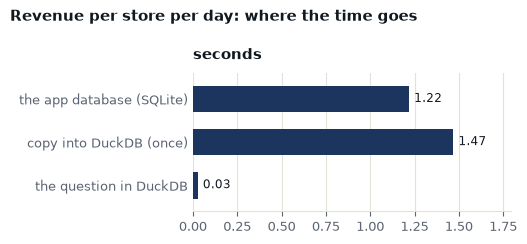

In [5]:
V.bars({"way": list(times), "seconds": list(times.values())}, "way", ["seconds"],
       suptitle="Revenue per store per day: where the time goes", fmt="{:.2f}")

🔍 The same answer in a fraction of the time, from a file several times smaller. The rows didn't change, only how
they are stored: DuckDB read the four columns the question names and skipped `order_id` and the notes, and
similar values side by side compressed well (the slides' column board).

Two more things make it fast. It runs **in your Python process**, like SQLite: no server, nothing to install but the
package. And it works on batches of about 2,048 values at a time, on every CPU core.

🎓 Ask before the DuckDB cell: "bigger or smaller file?" Most rooms say bigger ("an analytics engine must add
indexes"). The smaller file is the column store's compression, from the slides. Keep the OLTP/OLAP point: the app
database is right for the app, wrong for this question.

## 2 · A connection and a database file

In [6]:
duckdb.sql("SELECT 42 AS answer, 'مرحبا' AS greeting")

answerINTEGER,greetingVARCHAR
42,مرحبا


Three daily order exports from Qafila's stores. On the third day the export gained a column.

In [7]:
FILES = {
    "orders_2026-09-14.csv": """order_id,store_id,status,amount,delivery_fee
101,RUH-04,delivered,275.86,9.00
102,JED-03,delivered,33.65,9.00
103,RUH-04,cancelled,12.00,0.00
""",
    "orders_2026-09-15.csv": """order_id,store_id,status,amount,delivery_fee
104,RUH-04,delivered,58.10,9.00
105,DMM-01,delivered,19.90,free
106,JED-03,delivered,44.00,9.00
""",
    "orders_2026-09-16.csv": """order_id,store_id,status,amount,delivery_fee,promo_code
107,RUH-04,delivered,8.75,9.00,YAWM96
108,JED-03,delivered,120.00,0.00,
109,DMM-01,delivered,61.25,9.00,YAWM96
110,RUH-04,cancelled,15.50,0.00,
""",
}
for name, text in FILES.items():
    (OUT / name).write_text(text, encoding="utf-8")
U.peek(OUT / "orders_2026-09-14.csv", 4)

order_id,store_id,status,amount,delivery_fee
101,RUH-04,delivered,275.86,9.00
102,JED-03,delivered,33.65,9.00
103,RUH-04,cancelled,12.00,0.00


In [8]:
duckdb.sql(f"SELECT * FROM '{F}/orders_2026-09-14.csv'")

order_idBIGINT,store_idVARCHAR,statusVARCHAR,amountDOUBLE,delivery_feeDOUBLE
101,RUH-04,delivered,275.86,9.0
102,JED-03,delivered,33.65,9.0
103,RUH-04,cancelled,12.0,0.0


🔍 No `CREATE TABLE`, no import: a file path in `FROM` is a table.

`duckdb.sql()` uses a default connection that lives in memory. A pipeline opens its own **connection**, in memory
or to a **database file**.

🤔 **Predict** · We create a table in an in-memory connection, close it and connect again. Is the table there?

In [9]:
mem = duckdb.connect()                 # in memory
mem.sql("CREATE TABLE hello AS SELECT 42 AS answer")
mem.close()

mem = duckdb.connect()
try:
    mem.sql("FROM hello")
except duckdb.CatalogException as e:
    print("❌", str(e).splitlines()[0])

❌ Catalog Error: Table with name hello does not exist!


In [10]:
DB = OUT / "qafila_toy.duckdb"
with duckdb.connect(str(DB)) as con:   # a file: created if it doesn't exist
    con.sql("CREATE TABLE hello AS SELECT 42 AS answer")

with duckdb.connect(str(DB)) as con:
    print(con.sql("FROM hello").fetchall(), "| file:", DB.name, f"{U.size_mb(DB):.2f} MB")

[(42,)] | file: qafila_toy.duckdb 0.27 MB


🔍 An in-memory database disappears with its connection: right for exploring and for tests. A `.duckdb` file
keeps every table in one file, like SQLite. The course's warehouse is `warehouse/qafila.duckdb`.

| Code | Gives |
|---|---|
| `duckdb.sql(...)` | the default in-memory connection: quick looks |
| `duckdb.connect()` | a new in-memory database |
| `duckdb.connect("x.duckdb")` | a database file, created if missing |
| `duckdb.connect("x.duckdb", read_only=True)` | the same file, without the right to change it (§4) |
| `with duckdb.connect(...) as con:` | closes the connection at the end of the block |

## 3 · Files where they are: CSV, globs, JSON, Parquet

A CSV has no types, so DuckDB **sniffs** them from a sample of rows. `DESCRIBE` shows what it decided.

🤔 **Predict** · On 15 September one fee says `free`. Which type does `delivery_fee` get in that file?

In [11]:
con = duckdb.connect()                 # in memory, for the rest of the notebook
for day in ["2026-09-14", "2026-09-15"]:
    types = con.sql(f"SELECT column_name, column_type FROM (DESCRIBE FROM '{F}/orders_{day}.csv')").fetchall()
    print(day, dict(types))

2026-09-14 {'order_id': 'BIGINT', 'store_id': 'VARCHAR', 'status': 'VARCHAR', 'amount': 'DOUBLE', 'delivery_fee': 'DOUBLE'}
2026-09-15 {'order_id': 'BIGINT', 'store_id': 'VARCHAR', 'status': 'VARCHAR', 'amount': 'DOUBLE', 'delivery_fee': 'VARCHAR'}


🔍 One value that isn't a number turns the whole column into `VARCHAR`, without an error. **Always check the types**
before trusting a file. Then take the decision yourself: state the type, and convert the odd values on purpose.

In [12]:
con.sql(f"""
    SELECT order_id, delivery_fee AS as_sent,
           coalesce(TRY_CAST(delivery_fee AS DECIMAL(6, 2)), 0) AS delivery_fee_sar
    FROM read_csv('{F}/orders_2026-09-15.csv', types = {{'delivery_fee': 'VARCHAR'}})""")

order_idBIGINT,as_sentVARCHAR,"delivery_fee_sarDECIMAL(12,2)"
104,9.00,9.00
105,free,0.00
106,9.00,9.00


🔍 `TRY_CAST` gives `NULL` where a cast fails, so the decision ("free" means 0) is written in the SQL, where it can
be read and tested.

A **glob** reads every daily file at once.

🤔 **Predict** · The third file has a `promo_code` column the others don't. What happens?

In [13]:
con.sql(f"SELECT * FROM read_csv('{F}/orders_*.csv')")

order_idBIGINT,store_idVARCHAR,statusVARCHAR,amountDOUBLE,delivery_feeVARCHAR
101,RUH-04,delivered,275.86,9.00
102,JED-03,delivered,33.65,9.00
103,RUH-04,cancelled,12.0,0.00
104,RUH-04,delivered,58.1,9.00
105,DMM-01,delivered,19.9,free
106,JED-03,delivered,44.0,9.00
107,RUH-04,delivered,8.75,9.00
108,JED-03,delivered,120.0,0.00
109,DMM-01,delivered,61.25,9.00
110,RUH-04,cancelled,15.5,0.00


🔍 No error, ten rows, and no `promo_code`. The columns came from the **first** file, and the third file's extra
column was silently dropped. (One `free` in one file also made `delivery_fee` text in all of them.)

`union_by_name = true` takes the columns of **all** files, matched by name, with `NULL` where a file lacks one.
`filename = true` adds the file each row came from, so you can trace a bad row back to its file.

In [14]:
con.sql(f"""
    SELECT order_id, store_id, amount, promo_code, parse_filename(filename) AS file
    FROM read_csv('{F}/orders_*.csv', union_by_name = true, filename = true)
    ORDER BY order_id""")

order_idBIGINT,store_idVARCHAR,amountDOUBLE,promo_codeVARCHAR,fileVARCHAR
101,RUH-04,275.86,NULL,orders_2026-09-14.csv
102,JED-03,33.65,NULL,orders_2026-09-14.csv
103,RUH-04,12.0,NULL,orders_2026-09-14.csv
104,RUH-04,58.1,NULL,orders_2026-09-15.csv
105,DMM-01,19.9,NULL,orders_2026-09-15.csv
106,JED-03,44.0,NULL,orders_2026-09-15.csv
107,RUH-04,8.75,YAWM96,orders_2026-09-16.csv
108,JED-03,120.0,NULL,orders_2026-09-16.csv
109,DMM-01,61.25,YAWM96,orders_2026-09-16.csv
110,RUH-04,15.5,NULL,orders_2026-09-16.csv


➕ **JSON** keeps its nesting: an object becomes a `STRUCT` (read it with a dot), a list becomes a `LIST` (`unnest`
gives one row per element). The app's API sends orders like this:

In [15]:
(OUT / "order_details.jsonl").write_text(
    '{"order_id": 104, "courier": {"id": "C-17", "vehicle": "bike"}, '
    '"items": [{"sku": "TEA-01", "qty": 2}, {"sku": "DATES-1KG", "qty": 1}]}\n'
    '{"order_id": 105, "courier": {"id": "C-22", "vehicle": "car"}, "items": [{"sku": "MILK-2L", "qty": 3}]}\n',
    encoding="utf-8")
display(con.sql(f"SELECT column_name, column_type FROM (DESCRIBE FROM '{F}/order_details.jsonl')"))
con.sql(f"""
    SELECT order_id, courier.vehicle, unnest(items, recursive := true)
    FROM '{F}/order_details.jsonl'""")

column_nameVARCHAR,column_typeVARCHAR
order_id,BIGINT
courier,"STRUCT(id VARCHAR, vehicle VARCHAR)"
items,"STRUCT(sku VARCHAR, qty BIGINT)[]"


order_idBIGINT,vehicleVARCHAR,skuVARCHAR,qtyBIGINT
104,bike,TEA-01,2
104,bike,DATES-1KG,1
105,car,MILK-2L,3


➕ **Parquet** is a column store in a file, the format of the slides' second part and Lab 1.2. `COPY ... TO` writes
any query to a file. Reading it back needs no options, because the types are stored in the file.

In [16]:
con.sql(f"""COPY (SELECT * FROM read_csv('{F}/orders_*.csv', union_by_name = true))
            TO '{F}/orders.parquet' (FORMAT parquet)""")
con.sql(f"SELECT column_name, column_type FROM (DESCRIBE FROM '{F}/orders.parquet')")

column_nameVARCHAR,column_typeVARCHAR
order_id,BIGINT
store_id,VARCHAR
status,VARCHAR
amount,DOUBLE
delivery_fee,VARCHAR
promo_code,VARCHAR


| Source | Read with | Notes |
|---|---|---|
| CSV | `FROM 'x.csv'`, `read_csv(...)` | types sniffed: check with `DESCRIBE` |
| JSON, JSON lines | `FROM 'x.json'`, `read_json(...)` | objects → `STRUCT`, lists → `LIST` |
| Parquet | `FROM 'x.parquet'`, `read_parquet(...)` | types stored in the file |
| Many files | `'orders_*.csv'`, `['a.csv', 'b.csv']` | `union_by_name`, `filename` |
| HTTP, S3, GCS, Azure | `FROM 'https://…'`, `'s3://…'` | the `httpfs` extension, loaded on first use |
| Write | `COPY (query) TO 'x.parquet'` | also CSV, JSON; `PARTITION_BY` in Lab 1.2 |

🎓 Lab 1.1 meets the real `free`: week 38's supplier prices are `VARCHAR` because of decimal commas. Let the room
make the link themselves: "where have we seen a number column become text?"

## 4 · Tables, views, other databases, and one writer at a time

A **table** is a copy, taken once. A **view** is a saved query, run again each time it is used.

In [17]:
wh = duckdb.connect(str(DB))
wh.sql(f"CREATE TABLE orders AS FROM read_csv('{F}/orders_*.csv', union_by_name = true)")
wh.sql(f"CREATE VIEW orders_live AS FROM read_csv('{F}/orders_*.csv', union_by_name = true)")
wh.sql("SELECT (SELECT count(*) FROM orders) AS in_table, (SELECT count(*) FROM orders_live) AS in_view")

in_tableBIGINT,in_viewBIGINT
10,10


🤔 **Predict** · Thursday's export arrives. How many orders do the table and the view count now?

In [18]:
(OUT / "orders_2026-09-17.csv").write_text(
    "order_id,store_id,status,amount,delivery_fee,promo_code\n111,JED-03,delivered,27.40,9.00,\n", encoding="utf-8")
wh.sql("SELECT (SELECT count(*) FROM orders) AS in_table, (SELECT count(*) FROM orders_live) AS in_view")

in_tableBIGINT,in_viewBIGINT
10,11


🔍 The table is fast and doesn't change under you; the view always shows the files as they are now. dbt (Day 2)
makes the same choice per model.

➕ **Other databases** can be attached and joined with yours, with no export and no import. That is how §1 copied
the app database: `ATTACH` with `TYPE sqlite` (PostgreSQL and MySQL work the same way).

In [19]:
wh.sql(f"ATTACH '{APP.as_posix()}' AS app (TYPE sqlite, READ_ONLY)")
display(wh.sql("SELECT database_name, schema_name, table_name FROM duckdb_tables() ORDER BY ALL"))
wh.sql("""
    SELECT o.store_id, count(*) AS toy_orders, any_value(a.n) AS orders_in_app
    FROM orders o
    JOIN (SELECT store_id, count(*) AS n FROM app.orders GROUP BY ALL) a USING (store_id)
    GROUP BY ALL ORDER BY ALL""")

database_nameVARCHAR,schema_nameVARCHAR,table_nameVARCHAR
app,main,orders
qafila_toy,main,hello
qafila_toy,main,orders


store_idVARCHAR,toy_ordersBIGINT,orders_in_appBIGINT
DMM-01,2,200000
JED-03,3,200000
RUH-04,5,200000


**Break it on purpose.** Only **one process** at a time can change a `.duckdb` file. Our notebook holds `wh`, a
read-write connection to `qafila_toy.duckdb`. Now a second program (a dbt run, a dashboard, another notebook)
opens the same file.

🤔 **Predict** · It only wants to read. Does it get in?

In [20]:
READER = f"import duckdb; print(duckdb.connect(r'{DB}', read_only=True).sql('SELECT count(*) FROM orders').fetchall()[0])"
other = subprocess.run([sys.executable, "-c", READER], capture_output=True, text=True)
print("❌" if other.returncode else "✅", other.stdout.strip() or first_error(other.stderr))

❌ _duckdb.IOException: IO Error: Cannot open file "…/qafila_toy.duckdb": The process cannot access the file because it is being used by another process.


🔍 Refused: while one process may write, no other process may open the file, not even to read. Close our
connection and try again:

In [21]:
wh.close()
other = subprocess.run([sys.executable, "-c", READER], capture_output=True, text=True)
print("❌" if other.returncode else "✅", other.stdout.strip() or first_error(other.stderr))

✅ (10,)


🔍 This is the most common DuckDB error in class: a notebook keeps the warehouse open, and `dbt run` or Dagster
fails with "Could not set lock on file" ("being used by another process" on Windows). To avoid it:
- open, query, close: `with duckdb.connect(path) as con:`;
- readers use `read_only=True` (many read-only processes can share a file);
- when many people or services must write, use a server (PostgreSQL, MotherDuck, a warehouse) or a table format
  like Iceberg (Day 3).

## 5 · Results into Python

A query shows as a table in the notebook. When the next step is Python code, take the rows out:

In [22]:
revenue = con.sql(f"""
    SELECT store_id, round(sum(amount), 2) AS revenue
    FROM read_csv('{F}/orders_*.csv', union_by_name = true)
    WHERE status = 'delivered'
    GROUP BY ALL ORDER BY revenue DESC""")
print(revenue.fetchall())
print("top store:", revenue.fetchall()[0][0])

[('RUH-04', 342.71), ('JED-03', 225.05), ('DMM-01', 81.15)]
top store: RUH-04


| Call | Gives |
|---|---|
| `.fetchall()` | a list of rows, each a tuple: `[0][0]` is the first value of the first row |
| `.df()` | a table Python can chart or save (a pandas DataFrame; the labs only display it) |
| `.pl()` | a Polars DataFrame (Day 2) |
| `.columns` | the column names |

➕ **Parameters.** A value from Python (a date, a store picked in a dashboard) goes in as a `?`, not pasted into the
SQL string: no quoting bugs and no SQL injection.

In [23]:
store = "JED-03"
con.execute(f"SELECT order_id, amount FROM read_csv('{F}/orders_*.csv', union_by_name = true) WHERE store_id = ?",
            [store]).fetchall()

[(102, 33.65), (106, 44.0), (108, 120.0), (111, 27.4)]

## 6 · Friendly SQL ➕

DuckDB's SQL is PostgreSQL-like, plus shortcuts the labs use.

In [24]:
con.sql(f"CREATE OR REPLACE TABLE o AS FROM read_csv('{F}/orders_*.csv', union_by_name = true)")
con.sql("""
    FROM o                                         -- FROM first; SELECT * is implied
    SELECT * EXCLUDE (delivery_fee, promo_code)    -- every column but these
    WHERE status = 'delivered'
    LIMIT 3""")

order_idBIGINT,store_idVARCHAR,statusVARCHAR,amountDOUBLE
101,RUH-04,delivered,275.86
102,JED-03,delivered,33.65
104,RUH-04,delivered,58.1


In [25]:
con.sql("""
    SELECT store_id, status, count(*) AS orders
    FROM o
    GROUP BY ALL                                   -- group by every column that isn't aggregated
    ORDER BY ALL                                   -- order by every column, left to right""")

store_idVARCHAR,statusVARCHAR,ordersBIGINT
DMM-01,delivered,2
JED-03,delivered,4
RUH-04,cancelled,2
RUH-04,delivered,3


In [26]:
con.sql("SELECT column_name, column_type, min, max, approx_unique, null_percentage FROM (SUMMARIZE o)")

column_nameVARCHAR,column_typeVARCHAR,minVARCHAR,maxVARCHAR,approx_uniqueBIGINT,"null_percentageDECIMAL(9,2)"
order_id,BIGINT,101,111,11,0.00
store_id,VARCHAR,DMM-01,RUH-04,3,0.00
status,VARCHAR,cancelled,delivered,2,0.00
amount,DOUBLE,8.75,275.86,11,0.00
delivery_fee,VARCHAR,0.00,free,3,0.00
promo_code,VARCHAR,YAWM96,YAWM96,1,81.82


| Shortcut | Does |
|---|---|
| `FROM t` / `FROM t SELECT ...` | `SELECT * FROM t` / FROM written first |
| `SELECT * EXCLUDE (a)` | all columns but some |
| `GROUP BY ALL`, `ORDER BY ALL` | no need to repeat the columns |
| `DESCRIBE`, `SUMMARIZE` | the types / a profile of every column (Lab 1.1) |
| `QUALIFY` | filter on a window function (`00_sql_windows`, Lab 1.4) |

## 7 · Summary

| | |
|---|---|
| **It does** | SQL analytics on one machine, fast · files in place (CSV, JSON, Parquet, Iceberg) · attach SQLite / PostgreSQL · results into Python · data larger than memory, by spilling to disk |
| **It doesn't** | serve an app (many small writes from many users: that's PostgreSQL) · let several processes write one file · scale past one machine (Spark, Day 3) · ingest, schedule or test by itself (dlt, Dagster, dbt) |
| **In this course** | the dlt destination (Lab 1.3) · the engine under dbt (Lab 2.3) · the warehouse `warehouse/qafila.duckdb` · a reader of Iceberg tables (Lab 3.1) |
| **As a service** | MotherDuck; Snowflake, BigQuery, Redshift and Databricks SQL offer the same columnar SQL at company scale |

**Cheat sheet**

| Code | Does |
|---|---|
| `duckdb.connect()` / `duckdb.connect("x.duckdb", read_only=True)` | in memory / a database file |
| `FROM 'x.csv'`, `read_csv(..., types = {...})` | a file as a table; take the types into your own hands |
| `read_csv('*.csv', union_by_name = true, filename = true)` | many files, matched by column name, traced to their file |
| `CREATE TABLE t AS ...`, `CREATE VIEW v AS ...` | a copy / a saved query |
| `ATTACH 'app.sqlite' AS app (TYPE sqlite, READ_ONLY)` | another database, joinable |
| `COPY (query) TO 'x.parquet' (FORMAT parquet)` | write a file |
| `.fetchall()`, `.df()` | rows as tuples / a table to chart or save |
| `con.execute("... WHERE id = ?", [value])` | a parameter from Python |
| `DESCRIBE`, `SUMMARIZE` | the types / a profile of every column |

## Checkpoint

1. DuckDB answered faster than SQLite, from a smaller file. Why?
2. A column you expect to be numeric comes out as `VARCHAR`. What do you do, and what do you not do?
3. Daily files keep arriving: when is a table right, and when a view?
4. `dbt run` fails with "could not set lock on file". What is holding it, and what are two ways to avoid it?

Next: [Lab 1.1 · Platform tour with DuckDB](../D1_1_platform_tour.ipynb). Docs:
[Python API](https://duckdb.org/docs/stable/clients/python/overview) ·
[CSV import](https://duckdb.org/docs/stable/data/csv/overview) ·
[friendly SQL](https://duckdb.org/docs/stable/sql/dialect/friendly_sql) ·
[concurrency](https://duckdb.org/docs/stable/connect/concurrency).

**What you built:** the tables and the view in `qafila_toy.duckdb`.

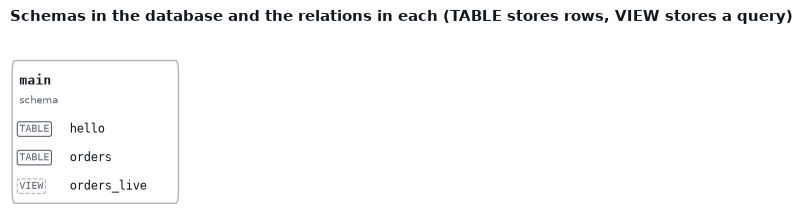

In [27]:
with duckdb.connect(str(DB), read_only=True) as db:
    V.database_map(db.sql("SELECT table_schema, table_name, table_type FROM information_schema.tables").df())